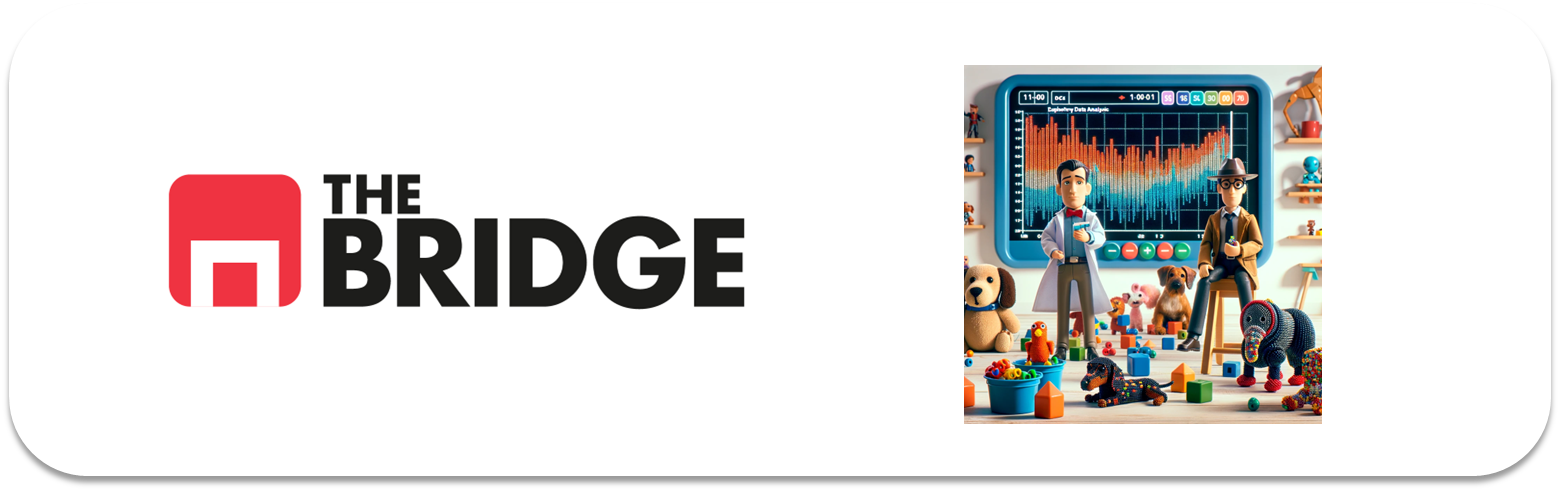

## Análisis de Datos (Bivariante): Numéricas. Correlaciones

En esta sesión vamos a analizar las variables numéricas de nuestro dataset y para ello vamos a utilizar dos herramientas el diagrama de dispersión y la correlación matemática. Pero ojo, eso es así por la naturaleza de nuestros datos, pero si nuestro dataset fuera por ejemplo de diferentes cotizaciones de empresas en los últimos 365 días entonces añadiríamos a lo anterior (de hecho lo haríamos lo primero) un gráfico de evolución temporal de las mismas en el que ambas estuvieran presentes.

Pues empecemos y para ello ya sabes preparar nuestro material (los datasets) e instrumental (liberías y funciones):

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_categorical_numerical_relationship, plot_combined_graphs, \
    pinta_distribucion_categoricas, plot_grouped_boxplots, grafico_dispersion_con_correlacion # Este módulo lo tienes en el directorio de los notebooks, puede abrirlo y jugar con las funciones que contiene

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

### Seguros: Bivariante CLV-Ingresos

En línea con investigar la relación entre `response` y `CLV` tenemos el análisis entre `CLV` e `ingresos`. Como en las otras veces:

**#1**  Tener la referencia de la **distribución de valores por separado de cada variable**

(2,)


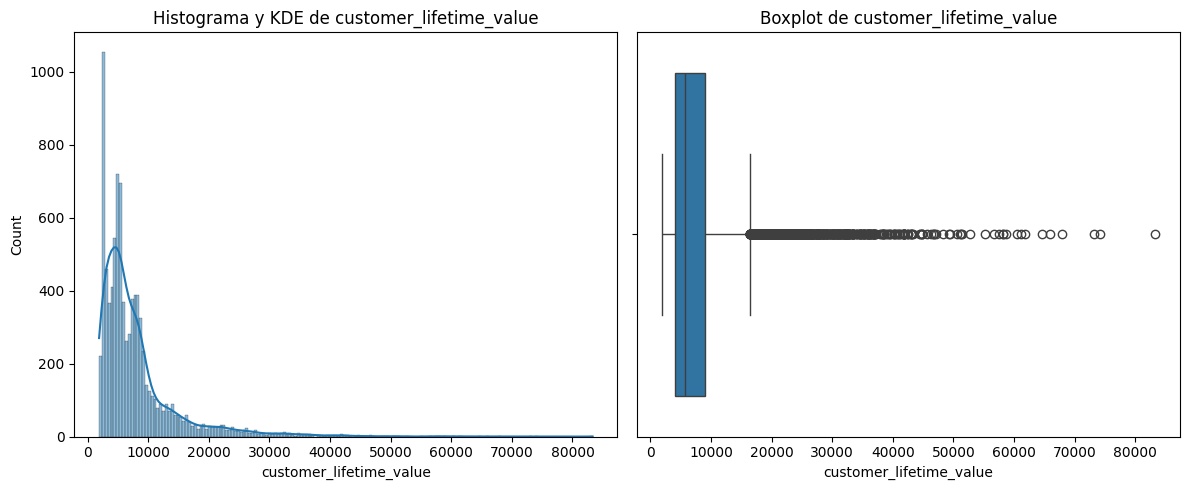

In [2]:
plot_combined_graphs(df_seguros,["customer_lifetime_value"])

(2,)


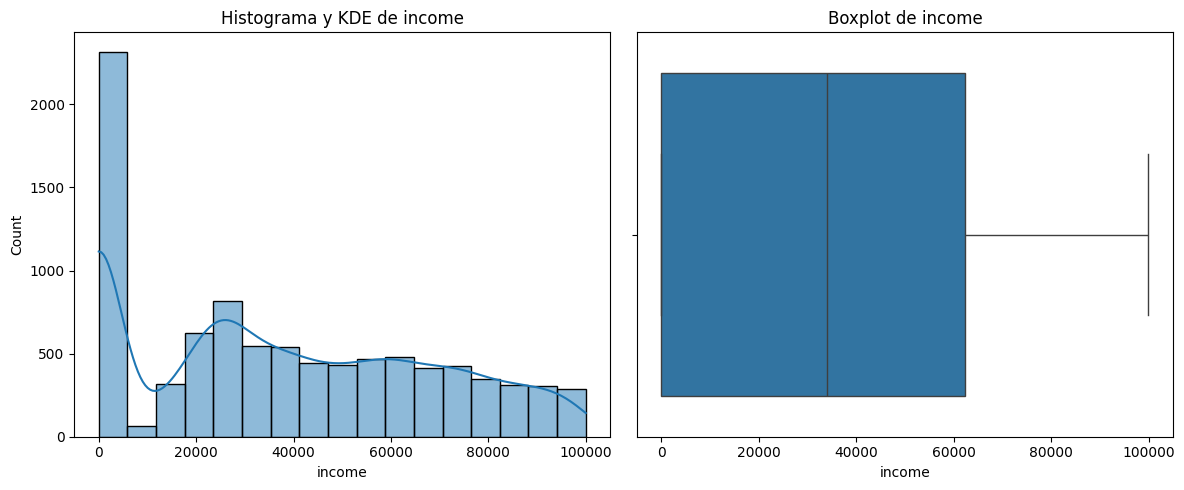

In [3]:
plot_combined_graphs(df_seguros,["income"])

**#2** Como ambas variables están medidas en la misma unidad mostramos **una comparación numérica de sus `describe`**:

In [4]:
df_seguros[["customer_lifetime_value","income"]].describe()

,customer_lifetime_value,income
count,9134.000000,9134.000000
mean,8004.940475,37657.380009
std,6870.967608,30379.904734
min,1898.007675,0.000000
25%,3994.251794,0.000000
50%,5780.182197,33889.500000
75%,8962.167041,62320.000000
max,83325.381190,99981.000000


**#3** Y ahora comparamos los datos unos con otros. **Utilizamos un diagrama de dispersión *scattered plot***

Un scatter plot, o diagrama de dispersión, es un tipo de gráfico en el que cada punto representa un observación individual, con la posición en el eje horizontal (X) indicando el valor de una variable y la posición en el eje vertical (Y) indicando el valor de la otra variable.



Los scatter plots son útiles para observar la relación entre dos variables numéricas. Se utilizan para detectar correlaciones, tendencias, agrupaciones, o para identificar patrones inusuales o valores atípicos (outliers) en los datos. 

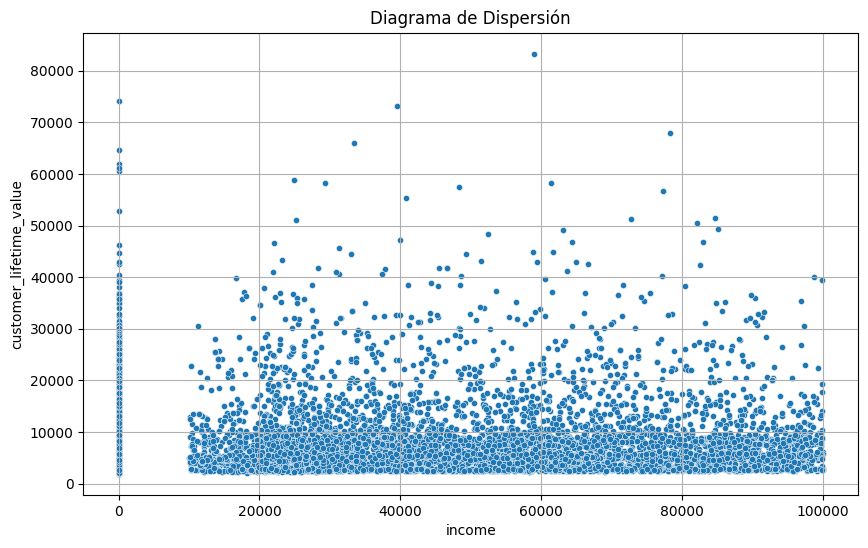

In [5]:
grafico_dispersion_con_correlacion(df_seguros,"income","customer_lifetime_value", 20)

Y bien, ¿qué opinas? 

### Correlación y relación entre variables numéricas


La [correlación](https://es.wikipedia.org/wiki/Correlaci%C3%B3n) trata de establecer la relación o **dependencia que existe entre las dos variables**. Es decir, determinar si los cambios en una de las variables influyen en los cambios de la otra. En caso de que suceda, diremos que las variables están correlacionadas o que hay correlación entre ellas. La correlación es **positiva** cuando los valores de las variables aumenta juntos; y es **negativa** cuando un valor de una variable se reduce cuando el valor de la otra variable aumenta.

De primeras se suele analizar usando un diagrama de dispersión como el mostrado y los ejemplos prototípicos son:

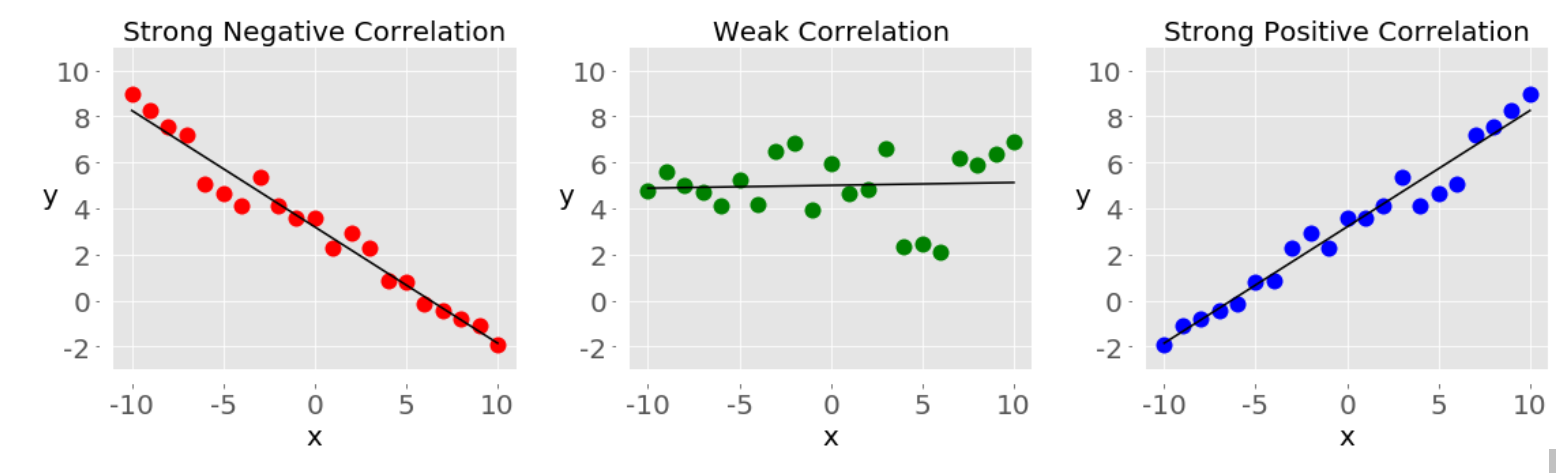

[En el primero se ve que al aumentar la variable x disminuye la y, se dice que hay una fuerte correlación negativa, en el segundo los cambios en x, no parecen afectar a los cambios en y, se dice que no hay correlación o que esta es muy débil, y finalmente cuando los cambios de x se relacionan con cambios de y en el mismo sentido se habla de una correlación fuerte]

¿A cuál de los tres se te parece el gráfico de dispersión de ingresos y CLV? A los dos de los extremos no, eso seguro. Por eso podemos pensar que no hay correlación entre ambos, es decir el CLV varía de forma similar y en rangos similares independientemente del income del cliente. 

Pero no acaba aquí la cosa hay un coeficiente matemático (de hecho hay varios) que miden esa relación. El más utilizado, y el que vamos a usar nosotros es el **coeficiente o correlación de Pearson**. Cuya fórmula te dejo aquí (no te asustes que usaremos funciones y métodos para obtenerlo):

$$r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \sum_{i=1}^{n} (y_i - \bar{y})^2}}$$


En esta fórmula:

- $r$ es el coeficiente de correlación de Pearson.
- $x_i$ y $y_i$ son los valores individuales de las dos variables.
- $\bar{x}$ y $\bar{y}$ son las medias de las variables `x` y `y`, respectivamente.
- $n$ es el número de observaciones (parejas de valores).

El coeficiente $r$ varía entre -1 y 1, donde_
* 1 significa una correlación positiva perfecta 
* -1 una correlación negativa perfecta
* 0 indica que no hay correlación **lineal** entre las variables. [marco lineal en negrita porque puede haber otro tipo de relación]

Y yendo a lo práctico, tenemos varias formas de obtener ese coeficiente:

In [6]:
df_seguros[["income","customer_lifetime_value"]].corr()

,income,customer_lifetime_value
income,1.000000,0.024366
customer_lifetime_value,0.024366,1.000000


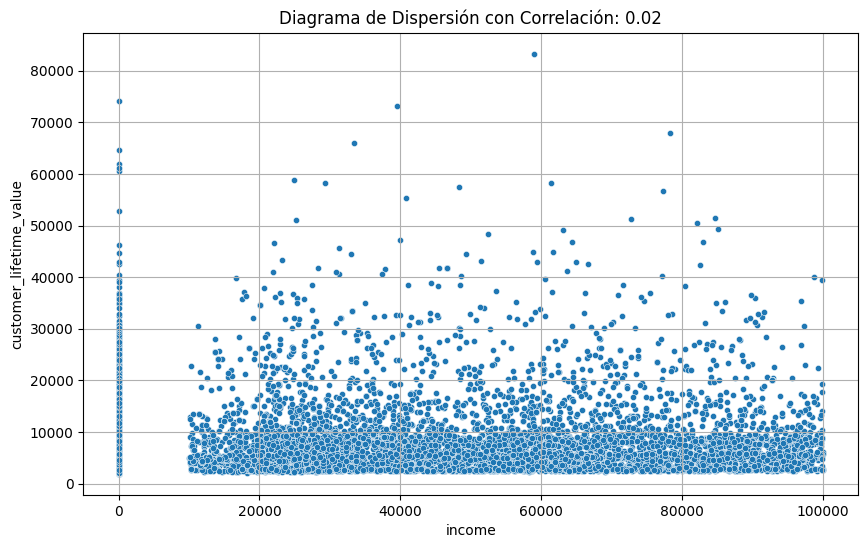

In [7]:
grafico_dispersion_con_correlacion(df_seguros,"income","customer_lifetime_value", 20, mostrar_correlacion = True)

Básicamente: no están correladas linealmente, lo cual ya nos lo podemos apuntar como un elemento más de nuestro análisis.

Pero no termina aquí el análisis. Fíjate en el salto entre 0 y el siguiente valor de income: hay muchísimos clientes con ingresos **exactamente 0**. Antes de decidir si es un error, un dato desconocido o un valor real, investiguemos quiénes son:

In [8]:
pd.crosstab(df_seguros["income"] == 0, df_seguros["employmentstatus"])

employmentstatus,Disabled,Employed,Medical Leave,Retired,Unemployed
income,,,,,
False,405,5698,432,282,0
True,0,0,0,0,2317


(2,)


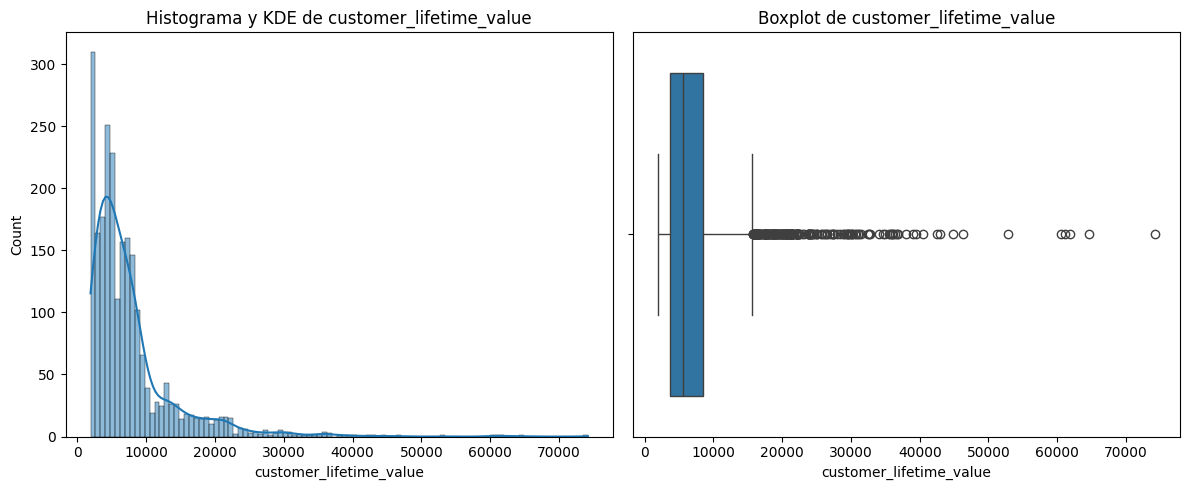

In [9]:
plot_combined_graphs(df_seguros.loc[df_seguros.income == 0], ["customer_lifetime_value"])

(2,)


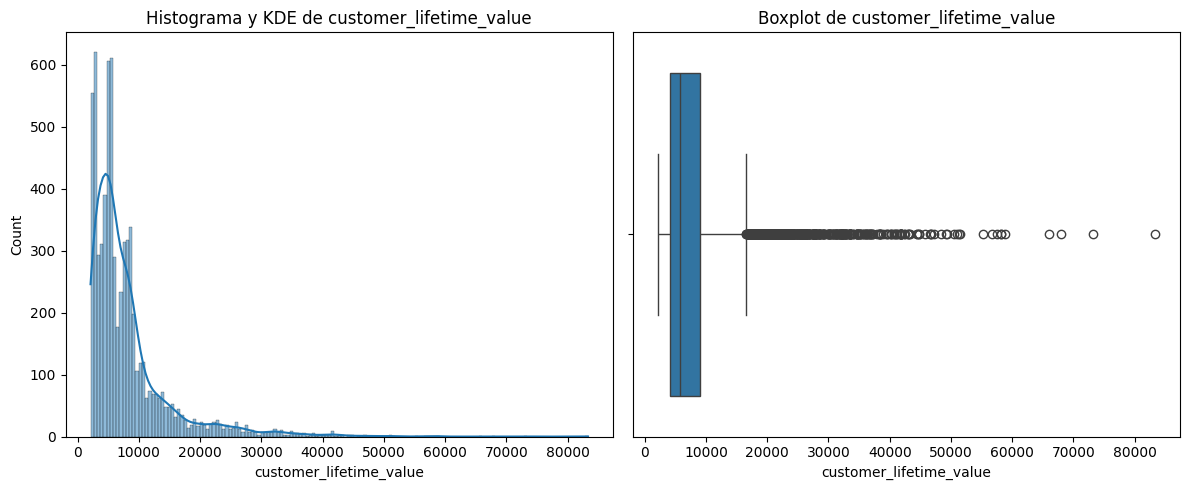

In [10]:
plot_combined_graphs(df_seguros.loc[df_seguros.income > 0], ["customer_lifetime_value"])

**Todos** los clientes con income 0 son parados (`Unemployed`) y **todos** los parados tienen income 0. No es un error ni un dato desconocido: es un valor real. Lo que ocurre es que la variable mezcla dos poblaciones distintas (clientes con y sin ingresos), y eso conviene tenerlo en cuenta: analizar income solo entre quienes tienen ingresos, o usar directamente `employmentstatus`.

> Lección que retomaremos en Data Cleaning: un valor "raro" no se trata hasta saber qué significa.

### Otras medidas de relación entre numéricas

#### Covarianza

La **covarianza** es la versión "en bruto" de la correlación: mide si dos variables se mueven en el mismo sentido (covarianza positiva) o en sentido contrario (negativa).

$$cov(x, y) = \frac{\sum\limits_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{n-1}$$

Si te fijas, es exactamente el numerador de la fórmula de Pearson. Pearson divide además por las desviaciones de cada variable, y eso es lo que lo deja entre -1 y 1. La covarianza **no está acotada y depende de las unidades** de las variables, así que su valor no se puede interpretar en términos de "mucha" o "poca" relación. Compruébalo:

In [11]:
print("Covarianza income - CLV:              ", round(df_seguros["income"].cov(df_seguros["customer_lifetime_value"]), 1))
print("Covarianza monthly_premium_auto - CLV:", round(df_seguros["monthly_premium_auto"].cov(df_seguros["customer_lifetime_value"]), 1))
print()
print("Correlación income - CLV:              ", round(df_seguros["income"].corr(df_seguros["customer_lifetime_value"]), 3))
print("Correlación monthly_premium_auto - CLV:", round(df_seguros["monthly_premium_auto"].corr(df_seguros["customer_lifetime_value"]), 3))

Covarianza income - CLV:               5086072.0
Covarianza monthly_premium_auto - CLV: 93682.6

Correlación income - CLV:               0.024
Correlación monthly_premium_auto - CLV: 0.396


La covarianza de income y CLV es enorme simplemente porque income se mide en decenas de miles; sin embargo, la correlación nos dice que la relación de verdad está entre la prima mensual y el CLV (≈ 0,40), no con income (≈ 0,02). **Moraleja: para analizar, usa la correlación.** La covarianza la verás aparecer "por dentro" de otros métodos más adelante.

#### Correlación de Spearman

Pearson mide relaciones **lineales** y es sensible a los valores extremos. La correlación de **Spearman** calcula la misma correlación pero sobre las **posiciones** (rangos) de los valores en lugar de sobre los valores. Así mide si la relación es **monótona** (cuando una sube, la otra tiende a subir, aunque no sea en línea recta) y le afectan mucho menos los outliers.

Uso práctico:
* Variables con distribuciones muy asimétricas o con outliers (como el CLV) → mira también Spearman.
* Si Pearson y Spearman se parecen, perfecto. Si difieren mucho, investiga: puede haber outliers o una relación no lineal.

In [12]:
pares = [("income", "customer_lifetime_value"),
         ("monthly_premium_auto", "customer_lifetime_value"),
         ("monthly_premium_auto", "total_claim_amount")]

for x, y in pares:
    pearson = df_seguros[x].corr(df_seguros[y])                       # method="pearson" por defecto
    spearman = df_seguros[x].corr(df_seguros[y], method="spearman")
    print(f"{x} - {y}: Pearson = {pearson:.2f} | Spearman = {spearman:.2f}")

income - customer_lifetime_value: Pearson = 0.02 | Spearman = 0.06
monthly_premium_auto - customer_lifetime_value: Pearson = 0.40 | Spearman = 0.45
monthly_premium_auto - total_claim_amount: Pearson = 0.63 | Spearman = 0.52


Y la pregunta que queda en el aire: income y CLV tienen una correlación de 0,02. ¿Eso es "cero" o es una relación pequeña pero real? ¿Y el 0,40 de la prima, nos lo podemos creer? Para responder hace falta saber si un resultado puede deberse a la casualidad, que es justo lo que vemos en el siguiente notebook: **`04_Real_o_Casualidad`**.